# Salary Satisfaction Classification

## Introduction & Objectives

This notebook uses job-posting information to classify a salary as **below** or **at/above** the median salary in the training data. We will clean the data, explore key variables, prepare features without leaking information from the test set, and compare four beginner-friendly classification models.

**Objectives**
- Clean salary estimates and create an average salary for each posting.
- Explore salary, company rating, job-title categories, and location.
- Split the data before learning the salary threshold or encoding categories.
- Train and compare Logistic Regression, K-Nearest Neighbors, Decision Tree, and Random Forest models.

> The target is relative to this dataset: “satisfactory” means at least the **training-set median**, not an external measure of salary satisfaction.


In [1]:
# 1. Import the libraries used throughout the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


In [2]:
# 2. Load the dataset and inspect its first rows and column types
# Place df.csv in the same folder as this notebook.
df_raw = pd.read_csv('df.csv')

display(df_raw.head())
df_raw.info()
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")


,Job Title,Salary Estimate,Rating,Company Name,Location,Size,Founded,Type of ownership,Industry,Sector,Revenue
0,Senior Data Scientist,$111K-$181K (Glassdoor est.),3.5,Hopper\n3.5,"New York, NY",501 to 1000 employees,2007,Company - Private,Travel Agencies,Travel & Tourism,Unknown / Non-Applicable
1,"Data Scientist, Product Analytics",$111K-$181K (Glassdoor est.),4.5,Noom US\n4.5,"New York, NY",1001 to 5000 employees,2008,Company - Private,"Health, Beauty, & Fitness",Consumer Services,Unknown / Non-Applicable
2,Data Science Manager,$111K-$181K (Glassdoor est.),-1.0,Decode_M,"New York, NY",1 to 50 employees,-1,Unknown,-1,-1,Unknown / Non-Applicable
3,Data Analyst,$111K-$181K (Glassdoor est.),3.4,Sapphire Digital\n3.4,"Lyndhurst, NJ",201 to 500 employees,2019,Company - Private,Internet,Information Technology,Unknown / Non-Applicable
4,"Director, Data Science",$111K-$181K (Glassdoor est.),3.4,United Entertainment Group\n3.4,"New York, NY",51 to 200 employees,2007,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5892 entries, 0 to 5891
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Job Title          5892 non-null   object 
 1   Salary Estimate    5892 non-null   object 
 2   Rating             5892 non-null   float64
 3   Company Name       5892 non-null   object 
 4   Location           5892 non-null   object 
 5   Size               5892 non-null   object 
 6   Founded            5892 non-null   object 
 7   Type of ownership  5892 non-null   object 
 8   Industry           5892 non-null   object 
 9   Sector             5892 non-null   object 
 10  Revenue            5892 non-null   object 
dtypes: float64(1), object(10)
memory usage: 506.5+ KB
Rows: 5,892 | Columns: 11


## Data Cleaning

The raw file contains salary estimates stored as text, missing estimates marked `-1`, and some hourly pay entries. We will keep salary ranges that can be interpreted consistently, convert their endpoints to numbers, and create an average salary (in thousands of dollars). We will also derive state and job-title categories, remove records without valid ratings, and remove duplicate rows.


In [3]:
# 3. Clean salary estimates and create numeric salary columns
# Exclude missing estimates and hourly estimates, which use a different pay scale.
df = df_raw.loc[df_raw['Salary Estimate'].notna()].copy()
salary_text = df['Salary Estimate'].astype(str).str.strip()
df = df.loc[(salary_text != '-1') & (~salary_text.str.contains('Per Hour', case=False, na=False))].copy()

# Remove currency/estimate notation, then extract the two endpoints of each range.
df['Salary Estimate'] = (df['Salary Estimate'].astype(str)
                         .str.replace('$', '', regex=False)
                         .str.replace('K', '', regex=False)
                         .str.replace(r'\s*\(.*?\)', '', regex=True)
                         .str.strip())
salary_parts = df['Salary Estimate'].str.extract(r'(\d+)\s*-\s*(\d+)')
df['Min_salary'] = pd.to_numeric(salary_parts[0], errors='coerce')
df['Max_salary'] = pd.to_numeric(salary_parts[1], errors='coerce')

# Keep only rows where both endpoints were successfully extracted.
df = df.dropna(subset=['Min_salary', 'Max_salary']).copy()
df['Average_salary'] = (df['Min_salary'] + df['Max_salary']) / 2

display(df[['Salary Estimate', 'Min_salary', 'Max_salary', 'Average_salary']].head())
print(f"Rows remaining after salary cleaning: {len(df):,}")


,Salary Estimate,Min_salary,Max_salary,Average_salary
0,111-181,111,181,146.0
1,111-181,111,181,146.0
2,111-181,111,181,146.0
3,111-181,111,181,146.0
4,111-181,111,181,146.0


Rows remaining after salary cleaning: 5,500


In [4]:
# 4. Extract state, remove invalid ratings, and remove duplicate records
# The text after the final comma is the state/region code in this dataset.
df['State'] = df['Location'].astype(str).str.split(',').str[-1].str.strip()
# Exclude locations that do not provide a usable US state code.
df = df.loc[df['State'].str.len().eq(2)].copy()

# A rating of -1 represents a missing rating in the source data.
df = df.loc[df['Rating'] != -1].copy()
df = df.drop_duplicates().copy()

print(f"Rows after location, rating, and duplicate checks: {len(df):,}")
display(df[['Location', 'State', 'Rating']].head())


Rows after location, rating, and duplicate checks: 4,859


,Location,State,Rating
0,"New York, NY",NY,3.5
1,"New York, NY",NY,4.5
3,"Lyndhurst, NJ",NJ,3.4
4,"New York, NY",NY,3.4
5,"New York, NY",NY,2.9


In [5]:
# 5. Group detailed job titles into a smaller set of useful categories
def categorize_job_title(job_title):
    """Return a broad job family based on keywords in the original title."""
    title = str(job_title).lower()
    if 'data scientist' in title or 'data science' in title:
        return 'data scientist'
    elif 'data engineer' in title:
        return 'data engineer'
    elif 'deep learning' in title:
        return 'deep learning engineer'
    elif 'machine learning' in title:
        return 'machine learning engineer'
    elif 'director' in title:
        return 'director'
    elif 'analyst' in title:
        return 'analyst'
    elif 'research' in title:
        return 'researcher'
    elif 'manager' in title:
        return 'manager'
    else:
        return 'other'

df['Job Title'] = df['Job Title'].apply(categorize_job_title)
cleaned_df = df[['Job Title', 'Rating', 'Average_salary', 'State']].copy()

# Different postings can share identical model inputs and salary. Remove these duplicates
# BEFORE the train/test split so identical rows cannot appear in both sets (data leakage).
rows_before = len(cleaned_df)
cleaned_df = cleaned_df.drop_duplicates().reset_index(drop=True)
print(f"Removed {rows_before - len(cleaned_df):,} duplicate rows after selecting modeling columns")
print('Clean dataset shape:', cleaned_df.shape)
display(cleaned_df.head())


Removed 835 duplicate rows after selecting modeling columns
Clean dataset shape: (4024, 4)


,Job Title,Rating,Average_salary,State
0,data scientist,3.5,146.0,NY
1,data scientist,4.5,146.0,NY
2,analyst,3.4,146.0,NJ
3,data scientist,3.4,146.0,NY
4,data scientist,2.9,146.0,NY


## Exploratory Data Analysis (EDA)

Exploratory plots help us understand the values and category balance before modeling. The salary estimates are expressed in thousands of dollars, and the rating plot shows only records with valid ratings. These visualizations describe this dataset; they do not establish cause and effect.


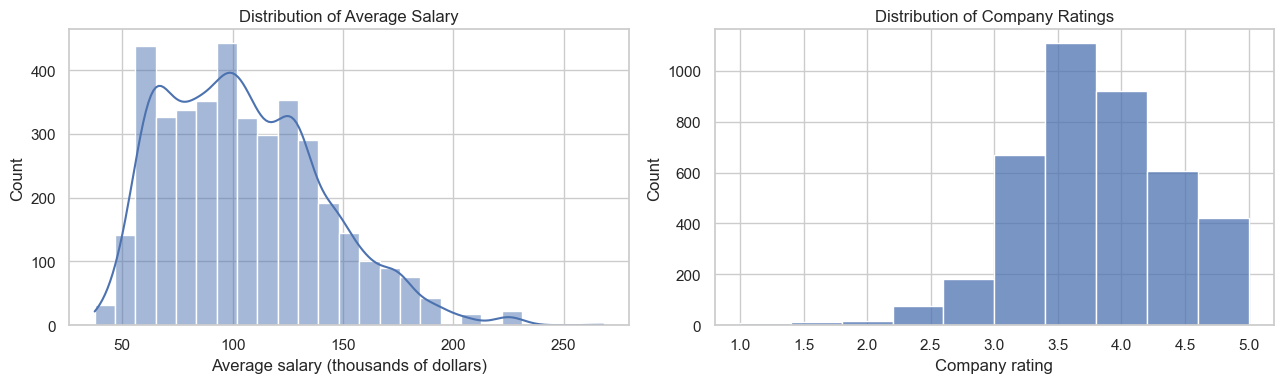

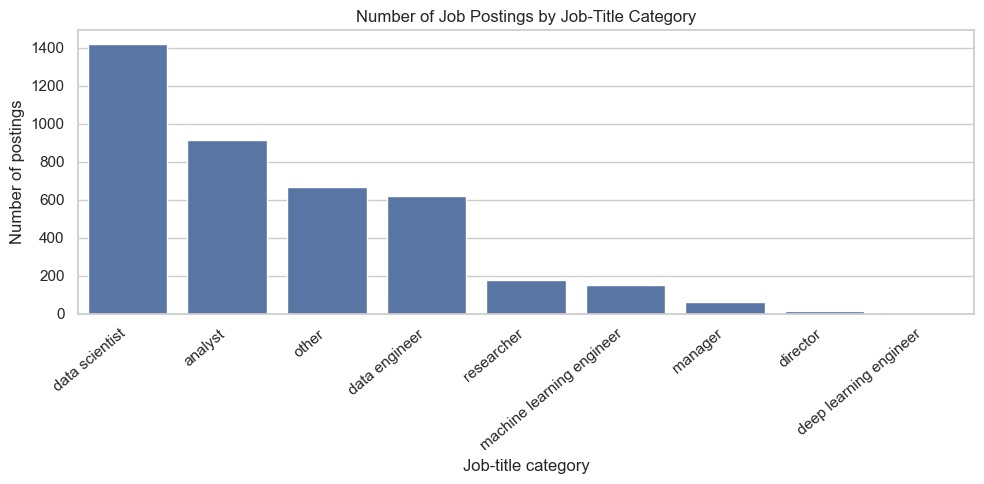

In [6]:
# 6. Plot the salary and rating distributions, then count job-title categories
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=cleaned_df, x='Average_salary', bins=25, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Average Salary')
axes[0].set_xlabel('Average salary (thousands of dollars)')
sns.histplot(data=cleaned_df, x='Rating', bins=10, kde=False, ax=axes[1])
axes[1].set_title('Distribution of Company Ratings')
axes[1].set_xlabel('Company rating')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
order = cleaned_df['Job Title'].value_counts().index
sns.countplot(data=cleaned_df, x='Job Title', order=order)
plt.title('Number of Job Postings by Job-Title Category')
plt.xlabel('Job-title category')
plt.ylabel('Number of postings')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()


## Feature Engineering & Train/Test Split (Preventing Data Leakage)

We will reserve 30% of the records as a test set. The average salary is separated from the input features before splitting. **Only the training salaries** determine the median threshold; that same fixed threshold is then applied to both training and test salaries. This prevents the test set from influencing how the target is defined.

The categorical columns (`Job Title` and `State`) will be one-hot encoded after the split. Test columns will then be aligned to the training columns, so the model sees the same feature layout without learning categories from test data.


In [7]:
# 7. Separate features and salary, then create the 70/30 train/test split
X = cleaned_df.drop(columns=['Average_salary'])
y_salary = cleaned_df['Average_salary']

X_train_raw, X_test_raw, salary_train, salary_test = train_test_split(
    X, y_salary, test_size=0.30, random_state=101
)
print('Training rows:', len(X_train_raw))
print('Test rows:', len(X_test_raw))


Training rows: 2816
Test rows: 1208


In [8]:
# 8. Learn the median from training data only and create the binary target
training_median_salary = salary_train.median()
y_train = (salary_train >= training_median_salary).astype(int)
y_test = (salary_test >= training_median_salary).astype(int)

print(f"Training-set median salary: {training_median_salary:.1f} thousand dollars")
print('Target meaning: 1 = at/above training median; 0 = below training median')
print('Training target counts:')
print(y_train.value_counts().sort_index())
print('Test target counts:')
print(y_test.value_counts().sort_index())


Training-set median salary: 101.0 thousand dollars
Target meaning: 1 = at/above training median; 0 = below training median
Training target counts:
Average_salary
0    1404
1    1412
Name: count, dtype: int64
Test target counts:
Average_salary
0    616
1    592
Name: count, dtype: int64


In [9]:
# 9. One-hot encode categories using training categories, then align the test set
categorical_columns = ['Job Title', 'State']
X_train = pd.get_dummies(X_train_raw, columns=categorical_columns, dtype=int)
X_test = pd.get_dummies(X_test_raw, columns=categorical_columns, dtype=int)

# Missing test categories get 0; extra test-only categories are not used.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print('Encoded training shape:', X_train.shape)
print('Encoded test shape:', X_test.shape)
print('Feature columns match:', X_train.columns.equals(X_test.columns))


Encoded training shape: (2816, 27)
Encoded test shape: (1208, 27)
Feature columns match: True


## Model 1 - Logistic Regression

Logistic Regression is a common baseline classifier. It estimates the probability that a posting belongs to either salary class. We fit it on the training data, then evaluate predictions on the held-out test data using a confusion matrix, classification report, and accuracy.


In [10]:
# 10. Train and evaluate Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

print('Confusion matrix:')
print(confusion_matrix(y_test, logistic_predictions))
print('Classification report:')
print(classification_report(y_test, logistic_predictions, zero_division=0))
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
print(f"Accuracy: {logistic_accuracy:.3f}")


Confusion matrix:
[[450 166]
 [186 406]]
Classification report:
              precision    recall  f1-score   support

           0       0.71      0.73      0.72       616
           1       0.71      0.69      0.70       592

    accuracy                           0.71      1208
   macro avg       0.71      0.71      0.71      1208
weighted avg       0.71      0.71      0.71      1208

Accuracy: 0.709


## Model 2 - K-Nearest Neighbors (KNN)

KNN predicts a class by looking at the labels of nearby training examples. Its default setting uses five neighbors. We evaluate it on the same untouched test set so its results can be compared fairly with the other models.


In [11]:
# 11. Train and evaluate K-Nearest Neighbors
knn_model = KNeighborsClassifier()
knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)

print('Confusion matrix:')
print(confusion_matrix(y_test, knn_predictions))
print('Classification report:')
print(classification_report(y_test, knn_predictions, zero_division=0))
knn_accuracy = accuracy_score(y_test, knn_predictions)
print(f"Accuracy: {knn_accuracy:.3f}")


Confusion matrix:
[[398 218]
 [198 394]]
Classification report:
              precision    recall  f1-score   support

           0       0.67      0.65      0.66       616
           1       0.64      0.67      0.65       592

    accuracy                           0.66      1208
   macro avg       0.66      0.66      0.66      1208
weighted avg       0.66      0.66      0.66      1208

Accuracy: 0.656


## Model 3 - Decision Tree

A Decision Tree makes predictions through a sequence of feature-based rules. It can model non-linear patterns and is relatively easy to interpret. The fixed random state makes results reproducible.


In [12]:
# 12. Train and evaluate a Decision Tree
tree_model = DecisionTreeClassifier(random_state=101)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

print('Confusion matrix:')
print(confusion_matrix(y_test, tree_predictions))
print('Classification report:')
print(classification_report(y_test, tree_predictions, zero_division=0))
tree_accuracy = accuracy_score(y_test, tree_predictions)
print(f"Accuracy: {tree_accuracy:.3f}")


Confusion matrix:
[[404 212]
 [226 366]]
Classification report:
              precision    recall  f1-score   support

           0       0.64      0.66      0.65       616
           1       0.63      0.62      0.63       592

    accuracy                           0.64      1208
   macro avg       0.64      0.64      0.64      1208
weighted avg       0.64      0.64      0.64      1208

Accuracy: 0.637


## Model 4 - Random Forest

Random Forest combines predictions from many decision trees. Averaging across trees can make predictions more stable than using a single tree. As with the other models, we evaluate it on the same test set.


In [13]:
# 13. Train and evaluate a Random Forest
forest_model = RandomForestClassifier(random_state=101)
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

print('Confusion matrix:')
print(confusion_matrix(y_test, forest_predictions))
print('Classification report:')
print(classification_report(y_test, forest_predictions, zero_division=0))
forest_accuracy = accuracy_score(y_test, forest_predictions)
print(f"Accuracy: {forest_accuracy:.3f}")


Confusion matrix:
[[363 253]
 [193 399]]
Classification report:
              precision    recall  f1-score   support

           0       0.65      0.59      0.62       616
           1       0.61      0.67      0.64       592

    accuracy                           0.63      1208
   macro avg       0.63      0.63      0.63      1208
weighted avg       0.63      0.63      0.63      1208

Accuracy: 0.631


## Summary & Comparison of Models

The table and bar chart below compare test accuracy for all four models. Accuracy is the share of test postings classified correctly; it is useful for a quick comparison, but should be interpreted alongside each model's classification report—especially if the two classes are imbalanced. The best score here is not a guarantee of performance on future data.


,Model,Test Accuracy
0,Logistic Regression,0.708609
1,K-Nearest Neighbors,0.655629
2,Decision Tree,0.637417
3,Random Forest,0.630795


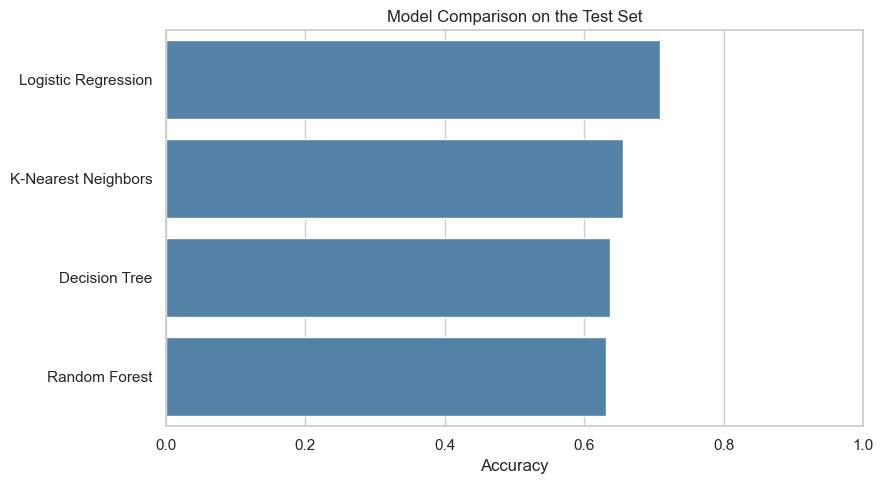

In [14]:
# 14. Compare test-set accuracy scores
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'K-Nearest Neighbors', 'Decision Tree', 'Random Forest'],
    'Test Accuracy': [logistic_accuracy, knn_accuracy, tree_accuracy, forest_accuracy]
}).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)

display(model_comparison)
plt.figure(figsize=(9, 5))
sns.barplot(data=model_comparison, x='Test Accuracy', y='Model', color='steelblue')
plt.xlim(0, 1)
plt.title('Model Comparison on the Test Set')
plt.xlabel('Accuracy')
plt.ylabel('')
plt.tight_layout()
plt.show()
